# Convoluciones: filtros y mapas de características

El módulo 3 dejó listo el pipeline de datos del jardín botánico. Ahora el mariposario vecino quiere sumarse a la app para clasificar también insectos y animales pequeños, y eso pide un modelo que reconozca bordes, texturas y manchas en cualquier parte de la foto. Las redes de los módulos anteriores no están hechas para eso. En `04-clasificacion-de-imagenes/02_experimentos_con_mnist` del módulo 2 desordenamos los píxeles de todas las imágenes con una misma permutación y la red densa aprendió igual de bien (97.35% contra 97.31%): para ella, que dos píxeles sean vecinos no significa nada.

Este notebook abre la pieza que aprovecha la vecindad de los píxeles, la **convolución**:

- por qué una capa densa no escala a fotos;
- la convolución a mano, con dos bucles, y la misma cuenta con `F.conv2d`;
- por qué PyTorch calcula en realidad una *correlación cruzada*, y por qué da igual;
- filtros que detectan bordes verticales y horizontales, y cómo leer un **mapa de características**;
- imágenes a color: un filtro recorre todos los canales a la vez;
- `nn.Conv2d` por dentro: forma de los pesos, cantidad de parámetros e inicialización;
- la fórmula del tamaño de la salida, el relleno y el paso;
- **parámetros compartidos**: una convolución es una capa densa con casi todos sus pesos en cero y el resto repetido;
- **equivariancia a traslaciones**: si el objeto se mueve, su mapa se mueve igual;
- una convolución que aprende sola un filtro de bordes, y por qué los últimos decimales le cuestan tanto.

Tarda menos de un minuto en una CPU.

**Contenido**

1. Preparación
2. Las capas densas no escalan a fotos
3. La convolución a mano
4. Una imagen real y `F.conv2d`
5. ¿Convolución o correlación cruzada?
6. Detectar bordes: mapas de características
7. Imágenes a color: un filtro recorre todos los canales
8. `nn.Conv2d` por dentro
9. El tamaño de la salida: relleno y paso
10. Parámetros compartidos
11. Equivariancia a traslaciones
12. La red aprende el filtro
13. Resumen y ejercicios

## 1. Preparación

Usamos dos conjuntos de datos que `torchvision` descarga la primera vez en `modulo-4/data`:

- **Fashion-MNIST**: fotos de ropa en escala de grises, de 28 × 28 píxeles, con el mismo formato que MNIST. Sirven para ver filtros sobre imágenes de un solo canal.
- **CIFAR-100**: fotos a color de 32 × 32 píxeles en 100 clases. De ahí sale el subconjunto de flores, insectos y mamíferos pequeños con el que trabaja el módulo. Aquí solo tomamos una foto, para ver qué cambia con tres canales.

También usamos `scipy.signal`, que tiene implementadas la convolución y la correlación cruzada "de libro", para comparar con PyTorch.

In [1]:
import math

import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torchvision import datasets
from scipy import signal
from PIL import Image
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("Versión de PyTorch:", torch.__version__)

RAIZ = "../data"       # modulo-4/data
moda = datasets.FashionMNIST(root=RAIZ, train=True, download=True)
cifar = datasets.CIFAR100(root=RAIZ, train=True, download=True)

print("Fashion-MNIST:", tuple(moda.data.shape), "  clases:", moda.classes)
print("CIFAR-100    :", cifar.data.shape, "  clases:", len(cifar.classes))


def miles(n):
    """Escribe un entero con punto de miles: 1234567 -> 1.234.567."""
    return f"{n:,}".replace(",", ".")

Versión de PyTorch: 2.11.0+cpu


Fashion-MNIST: (60000, 28, 28)   clases: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
CIFAR-100    : (50000, 32, 32, 3)   clases: 100


`moda.data` guarda las 60.000 imágenes de entrenamiento de Fashion-MNIST como enteros de 0 a 255, con forma `[60000, 28, 28]`. `cifar.data` guarda las 50.000 de CIFAR-100 como un arreglo de NumPy con forma `[50000, 32, 32, 3]`: alto, ancho y los tres canales al final, el orden de las imágenes comunes. PyTorch pone los canales primero, así que habrá que reordenar.

## 2. Las capas densas no escalan a fotos

En el módulo 2, `Flatten` ponía los píxeles en fila y cada neurona de la primera capa tenía un peso por píxel. Contemos cuántos pesos hacen falta a medida que crece la imagen, para una neurona, para una capa de 512 neuronas, y para una capa que entregue otra "imagen" del mismo tamaño que la entrada, que es lo que hace una capa convolucional:

In [2]:
casos = [("Fashion-MNIST, 1 × 28 × 28", 1 * 28 * 28),
         ("CIFAR-100, 3 × 32 × 32", 3 * 32 * 32),
         ("foto del módulo 3, 3 × 224 × 224", 3 * 224 * 224)]

print(f"{'entrada':34s}{'una neurona':>14s}{'512 neuronas':>16s}{'salida del mismo tamaño':>26s}")
for nombre, n in casos:
    print(f"{nombre:34s}{miles(n):>14s}{miles(n * 512):>16s}{miles(n * n):>26s}")

entrada                              una neurona    512 neuronas   salida del mismo tamaño
Fashion-MNIST, 1 × 28 × 28                   784         401.408                   614.656
CIFAR-100, 3 × 32 × 32                     3.072       1.572.864                 9.437.184
foto del módulo 3, 3 × 224 × 224         150.528      77.070.336            22.658.678.784


Una sola neurona sobre una foto de 224 × 224 en color ya tiene 150.528 pesos, y una capa que conserve el tamaño tendría más de 22 mil millones. Los apuntes de CS231n plantean la misma cuenta ([*Architecture Overview*](https://cs231n.github.io/convolutional-networks/#overview)): las redes densas "don't scale well to full images", una neurona sobre una imagen de 200 × 200 × 3 tendría 120.000 pesos, y tantos parámetros llevarían rápido al sobreajuste.

Además del tamaño está el experimento del módulo 2: la red densa trata cada píxel como una entrada sin relación con las demás. Pero en una foto los píxeles vecinos están relacionados: forman bordes, manchas, antenas, el contorno de un ala.

La idea de las redes convolucionales viene de la neurociencia. El libro de Goodfellow, Bengio y Courville cuenta ([sección 9.10](https://www.deeplearningbook.org/contents/convnets.html)) que Hubel y Wiesel registraron neuronas de la corteza visual de gatos y encontraron que respondían con fuerza a patrones muy específicos, como barras con una orientación precisa, y casi nada a otros. Las llamadas células simples hacen algo parecido a una función lineal de una región pequeña de la imagen, y las unidades de una red convolucional están diseñadas para imitarlas. Esa región pequeña, recorrida por toda la imagen, es la convolución.

## 3. La convolución a mano

Una convolución toma un **filtro** (o *kernel*), una grilla chica de números, por ejemplo de 3 × 3, y lo desliza sobre la imagen. En cada posición multiplica cada número del filtro por el píxel que tiene debajo, suma los nueve productos, y ese es el valor de la salida en esa posición.

Partimos de una imagen de 6 × 6 que es clara a la izquierda (10) y oscura a la derecha (0), y de un filtro con unos a la izquierda y menos unos a la derecha:

In [3]:
imagen = torch.tensor([[10., 10, 10, 0, 0, 0]] * 6)      # 6 × 6: clara a la izquierda, oscura a la derecha
filtro = torch.tensor([[1., 0, -1],
                       [1., 0, -1],
                       [1., 0, -1]])

ventana = imagen[0:3, 0:3]                                  # la esquina superior izquierda
print("ventana:\n", ventana)
print("ventana × filtro:\n", ventana * filtro)
print("suma:", (ventana * filtro).sum().item())

ventana:
 tensor([[10., 10., 10.],
        [10., 10., 10.],
        [10., 10., 10.]])
ventana × filtro:
 tensor([[ 10.,   0., -10.],
        [ 10.,   0., -10.],
        [ 10.,   0., -10.]])
suma: 0.0


En la esquina superior izquierda la ventana es toda clara: los 10 de la columna izquierda suman 30, los de la derecha restan 30, y queda 0. Un filtro así responde a **diferencias** entre izquierda y derecha, y en una región pareja da cero.

Ahora la deslizamos por todas las posiciones. La ventana de 3 × 3 cabe en 4 posiciones por fila y 4 por columna de una imagen de 6 × 6, así que la salida mide 4 × 4:

In [4]:
def convolucion_a_mano(imagen, filtro):
    alto, ancho = imagen.shape
    k_alto, k_ancho = filtro.shape
    salida = torch.zeros(alto - k_alto + 1, ancho - k_ancho + 1)
    for i in range(salida.shape[0]):              # fila de la esquina superior izquierda de la ventana
        for j in range(salida.shape[1]):          # columna de esa esquina
            ventana = imagen[i:i + k_alto, j:j + k_ancho]
            salida[i, j] = (ventana * filtro).sum()
    return salida


print(convolucion_a_mano(imagen, filtro))

tensor([[ 0., 30., 30.,  0.],
        [ 0., 30., 30.,  0.],
        [ 0., 30., 30.,  0.],
        [ 0., 30., 30.,  0.]])


La salida es 0 donde la ventana ve una región pareja y 30 en las dos columnas centrales, donde la ventana queda montada sobre el borde. Es un **mapa** de dónde está el borde vertical. El borde aparece con dos columnas de ancho porque hay dos posiciones de la ventana de tres columnas que quedan montadas sobre el salto de 10 a 0: la que tiene el salto entre su primera y su segunda columna, y la que lo tiene entre la segunda y la tercera. No es un efecto del tamaño de la imagen: en una de 20 × 20 con el mismo salto también salen dos columnas de 30, solo que se notan menos entre tantas columnas en cero.

El signo dice la dirección del cambio. Si damos vuelta la imagen, oscura a la izquierda y clara a la derecha, el mismo filtro da −30:

In [5]:
print(convolucion_a_mano(imagen.flip(1), filtro))

tensor([[  0., -30., -30.,   0.],
        [  0., -30., -30.,   0.],
        [  0., -30., -30.,   0.],
        [  0., -30., -30.,   0.]])


## 4. Una imagen real y `F.conv2d`

Probamos la función con una imagen de verdad, la primera de Fashion-MNIST, y la comparamos con `F.conv2d`, la convolución de PyTorch. `F.conv2d` trabaja con lotes y canales, como todo en PyTorch:

- la entrada tiene forma `[lote, canales, alto, ancho]`;
- los filtros tienen forma `[filtros de salida, canales de entrada, alto, ancho]` ([doc de `F.conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.conv2d.html)).

Con una imagen y un filtro, las dos formas son `[1, 1, 28, 28]` y `[1, 1, 3, 3]`.

In [6]:
bota = moda.data[0].float() / 255                      # [28, 28], valores entre 0 y 1
print("clase:", moda.classes[moda.targets[0]], "  forma:", tuple(bota.shape))

a_mano = convolucion_a_mano(bota, filtro)
con_pytorch = F.conv2d(bota.view(1, 1, 28, 28), filtro.view(1, 1, 3, 3))

print("a mano     :", tuple(a_mano.shape))
print("F.conv2d   :", tuple(con_pytorch.shape))
print("¿Iguales?  ", torch.allclose(a_mano, con_pytorch[0, 0], atol=1e-6))
print("productos calculados:", miles(26 * 26 * 9))

clase: Ankle boot   forma: (28, 28)
a mano     : (26, 26)
F.conv2d   : (1, 1, 26, 26)
¿Iguales?   True
productos calculados: 6.084


Las dos dan lo mismo. La salida mide 26 × 26 porque el filtro de 3 × 3 cabe en 26 posiciones a lo largo de 28 píxeles. Para obtenerla hubo que calcular 26 × 26 × 9 = 6.084 productos: los dos bucles de Python lo hacen de a uno, y `F.conv2d` hace todo en código compilado, para muchas imágenes y muchos filtros a la vez.

## 5. ¿Convolución o correlación cruzada?

Hay un detalle de nombres. En matemáticas, la convolución de una imagen $I$ con un filtro $K$ se define con el filtro **volteado** (Goodfellow y otros, [sección 9.1](https://www.deeplearningbook.org/contents/convnets.html), ecuación 9.5):

$$S(i, j) = \sum_m \sum_n I(i - m, j - n)\, K(m, n)$$

Lo que calculamos a mano, y lo que calcula PyTorch, es la misma suma sin voltear el filtro, que se llama **correlación cruzada** (ecuación 9.6):

$$S(i, j) = \sum_m \sum_n I(i + m, j + n)\, K(m, n)$$

La documentación de `nn.Conv2d` lo dice explícitamente: el operador que usa es "the valid 2D cross-correlation operator" ([`torch.nn.Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html)). "Valid" significa que solo se calculan las posiciones donde el filtro cabe entero, como en nuestra función. Lo comprobamos con `scipy.signal`, que tiene las dos operaciones, usando un filtro al azar (con un filtro simétrico no se notaría la diferencia):

In [7]:
torch.manual_seed(0)
k = torch.randn(3, 3)
pytorch = F.conv2d(bota.view(1, 1, 28, 28), k.view(1, 1, 3, 3))[0, 0]

correlacion = torch.from_numpy(signal.correlate2d(bota.numpy(), k.numpy(), mode="valid")).float()
convolucion = torch.from_numpy(signal.convolve2d(bota.numpy(), k.numpy(), mode="valid")).float()
volteado = F.conv2d(bota.view(1, 1, 28, 28), k.flip(0, 1).view(1, 1, 3, 3))[0, 0]

print("¿F.conv2d = correlación cruzada?             ", torch.allclose(pytorch, correlacion, atol=1e-5))
print("¿F.conv2d = convolución?                     ", torch.allclose(pytorch, convolucion, atol=1e-5))
print("¿F.conv2d con el filtro volteado = convolución?", torch.allclose(volteado, convolucion, atol=1e-5))

¿F.conv2d = correlación cruzada?              True
¿F.conv2d = convolución?                      False
¿F.conv2d con el filtro volteado = convolución? True


PyTorch calcula la correlación cruzada, y para obtener la convolución de libro basta voltear el filtro en las dos direcciones (`k.flip(0, 1)`).

¿Por qué casi todas las librerías la llaman "convolución" igual? Porque en una red los filtros se aprenden. Goodfellow y otros lo explican en la misma sección: una red que usa la convolución con volteo aprendería simplemente el filtro volteado del que aprendería una sin volteo. El resultado es el mismo, así que se usa la operación más directa. En este notebook seguimos esa costumbre y decimos "convolución" a lo que hace PyTorch.

## 6. Detectar bordes: mapas de características

El filtro de la sección 3 compara la columna izquierda con la derecha. Un filtro clásico para lo mismo es el de **Sobel**, que además le da el doble de peso a la fila central. Se puede escribir como el producto de dos vectores: uno que suaviza en vertical, $(1, 2, 1)$, y otro que resta en horizontal, $(-1, 0, 1)$. Su versión traspuesta detecta bordes horizontales:

In [8]:
suavizar = torch.tensor([1., 2., 1.])
restar = torch.tensor([-1., 0., 1.])

sobel_vertical = torch.outer(suavizar, restar)          # bordes verticales: compara izquierda con derecha
sobel_horizontal = sobel_vertical.T                     # bordes horizontales: compara arriba con abajo
print("bordes verticales:\n", sobel_vertical)
print("bordes horizontales:\n", sobel_horizontal)

bordes verticales:
 tensor([[-1.,  0.,  1.],
        [-2.,  0.,  2.],
        [-1.,  0.,  1.]])
bordes horizontales:
 tensor([[-1., -2., -1.],
        [ 0.,  0.,  0.],
        [ 1.,  2.,  1.]])


Con la correlación cruzada, el filtro de bordes verticales da un valor **positivo** donde la imagen se aclara de izquierda a derecha (la columna de la derecha tiene peso +1) y **negativo** donde se oscurece. El de bordes horizontales, positivo donde se aclara de arriba hacia abajo.

Aplicamos los dos a la bota. Usamos `padding=1`, que agrega un borde de ceros alrededor para que la salida mida 28 × 28 como la entrada (la sección 9 lo explica). Los dos filtros van juntos en un solo tensor de forma `[2, 1, 3, 3]`, así que `F.conv2d` entrega dos mapas de una vez. Al graficar, rojo es positivo, azul negativo y blanco cero:

forma de los mapas: (2, 28, 28)


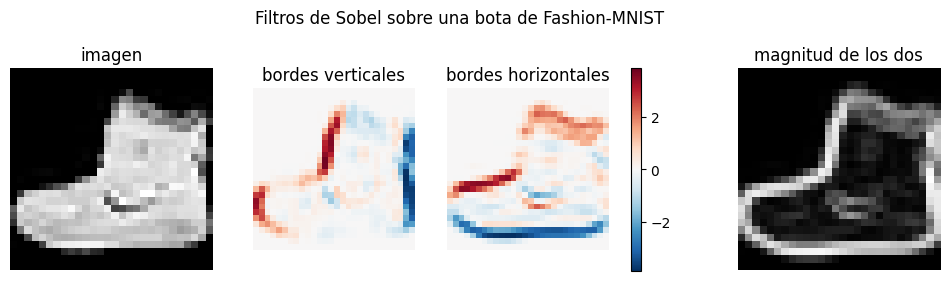

In [9]:
filtros_borde = torch.stack([sobel_vertical, sobel_horizontal]).unsqueeze(1)    # [2, 1, 3, 3]
mapas = F.conv2d(bota.view(1, 1, 28, 28), filtros_borde, padding=1)[0]       # [2, 28, 28]
magnitud = (mapas[0] ** 2 + mapas[1] ** 2).sqrt()
print("forma de los mapas:", tuple(mapas.shape))


def mostrar_mapas(imagen, mapas, magnitud, titulo):
    limite = mapas.abs().max().item()
    fig, ejes = plt.subplots(1, 4, figsize=(12, 3.3))
    ejes[0].imshow(imagen, cmap="gray")
    ejes[0].set_title("imagen")
    for eje, mapa, nombre in zip(ejes[1:3], mapas, ["bordes verticales", "bordes horizontales"]):
        im = eje.imshow(mapa, cmap="RdBu_r", vmin=-limite, vmax=limite)
        eje.set_title(nombre)
    ejes[3].imshow(magnitud, cmap="gray")
    ejes[3].set_title("magnitud de los dos")
    for eje in ejes:
        eje.axis("off")
    fig.colorbar(im, ax=ejes[1:3], shrink=0.8)
    fig.suptitle(titulo)
    plt.show()


mostrar_mapas(bota, mapas, magnitud, "Filtros de Sobel sobre una bota de Fashion-MNIST")

Cada mapa es un **mapa de características** (*feature map* o *activation map*): dice dónde y con qué intensidad aparece en la imagen el rasgo que busca su filtro.

- En el mapa de bordes verticales, el borde izquierdo de la bota sale en rojo (el fondo negro da paso a la bota clara) y el derecho en azul (la bota da paso al fondo). Las partes horizontales del contorno, como la suela, casi no aparecen.
- En el de bordes horizontales pasa lo contrario: la parte de arriba de la caña y la suela se marcan fuerte, y los costados casi nada.
- Las regiones parejas, el fondo y el interior de la bota, quedan en blanco: cero.
- La magnitud, $\sqrt{v^2 + h^2}$, junta los dos y dibuja el contorno completo.

Para verlo con números, seguimos una fila de la imagen, la 10, que cruza la caña de la bota:

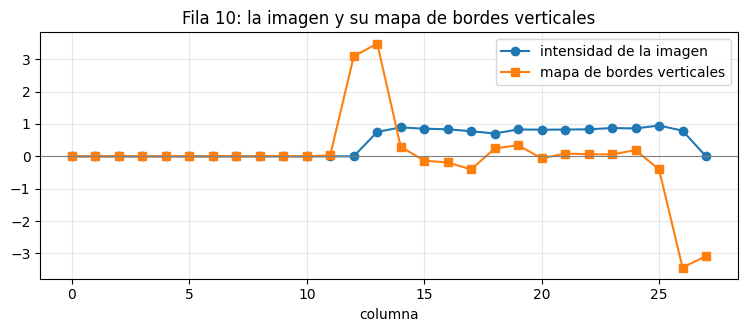

máximo del mapa: columna 13 (valor 3.49)
mínimo del mapa: columna 26 (valor -3.44)


In [10]:
fila = 10
fig, eje = plt.subplots(figsize=(9, 3.2))
eje.plot(bota[fila], marker="o", label="intensidad de la imagen")
eje.plot(mapas[0, fila], marker="s", label="mapa de bordes verticales")
eje.axhline(0, color="gray", linewidth=0.8)
eje.set_xlabel("columna")
eje.set_title(f"Fila {fila}: la imagen y su mapa de bordes verticales")
eje.legend()
eje.grid(alpha=0.3)
plt.show()

positivo, negativo = mapas[0, fila].argmax().item(), mapas[0, fila].argmin().item()
print(f"máximo del mapa: columna {positivo} (valor {mapas[0, fila, positivo]:.2f})")
print(f"mínimo del mapa: columna {negativo} (valor {mapas[0, fila, negativo]:.2f})")

En esa fila la bota va de la columna 13 a la 26. El máximo del mapa está en la columna 13, donde la intensidad sube de 0 a 0.8, y el mínimo en la 26, donde vuelve a bajar a 0. Entre medio, sobre la caña, la intensidad es casi plana y el mapa se queda cerca de cero. El filtro de bordes verticales es, en el fondo, una **derivada** horizontal suavizada: mide cuánto cambia la imagen al moverse a la derecha.

Lo mismo con una foto a color de CIFAR-100, un girasol. Por ahora la pasamos a escala de grises (la sección 7 muestra cómo lo hace una convolución) y le aplicamos los mismos filtros:

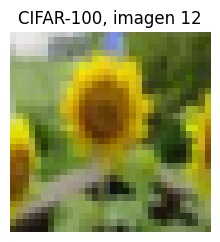

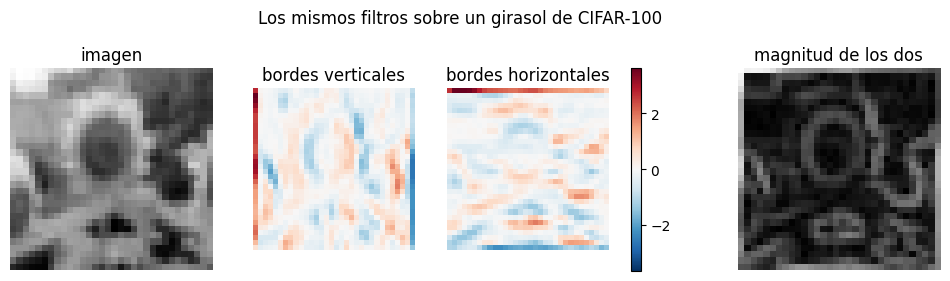

In [11]:
indice_girasol = cifar.targets.index(cifar.classes.index("sunflower"))
girasol = torch.from_numpy(cifar.data[indice_girasol]).permute(2, 0, 1).float() / 255     # [3, 32, 32]
girasol_gris = 0.299 * girasol[0] + 0.587 * girasol[1] + 0.114 * girasol[2]

mapas_girasol = F.conv2d(girasol_gris.view(1, 1, 32, 32), filtros_borde, padding=1)[0]
magnitud_girasol = (mapas_girasol[0] ** 2 + mapas_girasol[1] ** 2).sqrt()

plt.figure(figsize=(2.6, 2.6))
plt.imshow(girasol.permute(1, 2, 0))
plt.title(f"CIFAR-100, imagen {indice_girasol}")
plt.axis("off")
plt.show()
mostrar_mapas(girasol_gris, mapas_girasol, magnitud_girasol, "Los mismos filtros sobre un girasol de CIFAR-100")

Con solo 32 × 32 píxeles los bordes son más gruesos, pero en la magnitud se ve el contorno redondo del centro del girasol y el de sus pétalos. Tres cosas que no pasaban con la bota:

- **Los bordes más fuertes son falsos.** Las franjas rojas y azules del marco no están en la foto: las crea el relleno. `padding=1` agrega un marco de ceros de un píxel por lado (dos filas y dos columnas en total), que es negro, y la foto no es negra en sus orillas, así que el filtro ve un salto de intensidad en todo el contorno. En Fashion-MNIST no se notaba porque el fondo ya era negro. Es un costo del relleno con ceros que conviene tener presente al mirar mapas.
- En una foto natural los mapas casi no tienen zonas en blanco, como el fondo de Fashion-MNIST: hay pequeños cambios de intensidad por todos lados. Distinguir un borde de una textura ya no lo puede hacer un solo filtro, y para eso están las capas siguientes de una red.
- En el código, `permute(2, 0, 1)` pasa de `[alto, ancho, canales]` a `[canales, alto, ancho]`, el orden de PyTorch.

## 7. Imágenes a color: un filtro recorre todos los canales

Con una imagen a color, un filtro de 3 × 3 no mira un solo canal: tiene **un juego de 3 × 3 pesos por cada canal de entrada**, y suma los tres resultados. Así lo describe la documentación de `nn.Conv2d`: la salida de cada canal es el sesgo más la suma, sobre los canales de entrada, de la correlación cruzada de cada canal con su parte del filtro. Y los apuntes de CS231n lo resumen diciendo que la conexión es local en el alto y el ancho, "but always full along the entire depth of the input volume" ([*Local Connectivity*](https://cs231n.github.io/convolutional-networks/#conv)).

Lo comprobamos con una capa `nn.Conv2d` de 3 canales de entrada y 1 de salida, con pesos al azar:

In [12]:
torch.manual_seed(0)
capa_color = nn.Conv2d(in_channels=3, out_channels=1, kernel_size=3)
print("forma de los pesos:", tuple(capa_color.weight.shape), "  forma del sesgo:", tuple(capa_color.bias.shape))

x = girasol.unsqueeze(0)                                            # [1, 3, 32, 32]
de_una_vez = capa_color(x)

canal_por_canal = sum(F.conv2d(x[:, c:c + 1], capa_color.weight[:, c:c + 1]) for c in range(3))
canal_por_canal = canal_por_canal + capa_color.bias.view(1, -1, 1, 1)

print("salida:", tuple(de_una_vez.shape))
print("¿Igual a sumar los tres canales más el sesgo?", torch.allclose(de_una_vez, canal_por_canal, atol=1e-6))

forma de los pesos: (1, 3, 3, 3)   forma del sesgo: (1,)
salida: (1, 1, 30, 30)
¿Igual a sumar los tres canales más el sesgo? True


El filtro tiene forma `[1, 3, 3, 3]`: un filtro de salida, tres canales de entrada, 3 × 3. Aplicarlo es lo mismo que convolucionar cada canal con su parte del filtro y sumar. Por eso la salida tiene **un solo canal** aunque la entrada tenga tres: cada filtro produce un solo mapa de características.

Un caso extremo lo deja claro: un filtro de 1 × 1 no mira vecinos, solo combina los canales de cada píxel. La conversión a escala de grises de la sección 6 era exactamente eso. Pillow, la librería de imágenes que usa `torchvision`, convierte a gris con la fórmula $L = 0.299\,R + 0.587\,G + 0.114\,B$ ([`Image.convert`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.convert)). La escribimos como una convolución de 1 × 1 y la comparamos con la de Pillow:

In [13]:
a_gris = nn.Conv2d(3, 1, kernel_size=1, bias=False)
with torch.no_grad():
    a_gris.weight.copy_(torch.tensor([0.299, 0.587, 0.114]).view(1, 3, 1, 1))

con_convolucion = a_gris(x)[0, 0]
con_pillow = torch.from_numpy(np.array(Image.fromarray(cifar.data[indice_girasol]).convert("L"))).float() / 255

print("forma de los pesos:", tuple(a_gris.weight.shape))
print(f"diferencia máxima con Pillow: {(con_convolucion - con_pillow).abs().max():.4f}   (Pillow redondea a enteros: 0.5 / 255 = {0.5 / 255:.4f})")

forma de los pesos: (1, 3, 1, 1)
diferencia máxima con Pillow: 0.0020   (Pillow redondea a enteros: 0.5 / 255 = 0.0020)


Coinciden salvo por el redondeo de Pillow, que guarda el resultado como un entero entre 0 y 255. Una convolución de 1 × 1 es, en cada píxel, una capa lineal sobre los canales.

## 8. `nn.Conv2d` por dentro

Una capa convolucional tiene muchos filtros, y cada uno produce su propio mapa. Los parámetros de `nn.Conv2d` son:

| Parámetro | Qué es |
|---|---|
| `in_channels` | canales de la entrada: 1 en escala de grises, 3 en color, o los mapas de la capa anterior |
| `out_channels` | cuántos filtros tiene la capa, que es cuántos mapas produce |
| `kernel_size` | el tamaño de cada filtro; 3 es lo más común |
| `stride` | el **paso**: cuántos píxeles avanza el filtro de una posición a la siguiente |
| `padding` | el **relleno**: cuántos píxeles de ceros se agregan alrededor de la entrada |

La primera capa típica de una red para CIFAR, con 32 filtros de 3 × 3, paso 1 y relleno 1:

In [14]:
capa = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, stride=1, padding=1)
print(capa)
for nombre, parametro in capa.named_parameters():
    print(f"{nombre:7s} forma {str(tuple(parametro.shape)):15s} {parametro.numel():4d} números")
print("total:", sum(p.numel() for p in capa.parameters()))

Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
weight  forma (32, 3, 3, 3)    864 números
bias    forma (32,)             32 números
total: 896


Los pesos tienen forma `[32, 3, 3, 3]`: 32 filtros, cada uno con 3 × 3 pesos por cada uno de los 3 canales, o sea 27 pesos por filtro. Más un sesgo por filtro: 32 × 27 + 32 = 896 parámetros. Esa cuenta **no depende del tamaño de la imagen**: la misma capa sirve para 32 × 32 o para 224 × 224.

¿Cómo se inicializan? La documentación de `nn.Conv2d` dice que pesos y sesgos se sortean de una uniforme $\mathcal{U}(-\sqrt{k}, \sqrt{k})$ con $k = 1 / (C_\text{entrada} \cdot k_\text{alto} \cdot k_\text{ancho})$ (sección *Variables*). Es el mismo criterio de `nn.Linear` que vimos en `04-matematica-de-pytorch/02_capas_y_activaciones` del módulo 1 (sección 2), $\mathcal{U}(-1/\sqrt{n}, 1/\sqrt{n})$, con $n = 27$: la cantidad de números que ve cada filtro.

In [15]:
limite = math.sqrt(1 / (3 * 3 * 3))
print(f"límite teórico √(1/27): {limite:.4f}")
print(f"pesos : mínimo {capa.weight.min():.4f}   máximo {capa.weight.max():.4f}")
print(f"sesgos: mínimo {capa.bias.min():.4f}   máximo {capa.bias.max():.4f}")

límite teórico √(1/27): 0.1925
pesos : mínimo -0.1924   máximo 0.1924
sesgos: mínimo -0.1922   máximo 0.1891


Todos los valores caen dentro de ±0.1925. Pasamos un lote de 8 fotos de CIFAR-100 por la capa:

In [16]:
lote = torch.from_numpy(cifar.data[:8]).permute(0, 3, 1, 2).float() / 255        # [8, 3, 32, 32]
salida = capa(lote)
print("entrada:", tuple(lote.shape))
print("salida :", tuple(salida.shape))

entrada: (8, 3, 32, 32)
salida : (8, 32, 32, 32)


Cada una de las 8 imágenes sale convertida en 32 mapas de 32 × 32. Los canales de la salida ya no son colores: el canal $c$ es el mapa del filtro $c$. Así se ven los primeros 8 mapas del girasol, con los filtros todavía al azar:

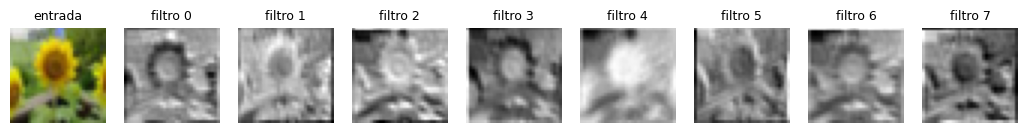

In [17]:
with torch.no_grad():
    mapas_azar = capa(girasol.unsqueeze(0))[0]

fig, ejes = plt.subplots(1, 9, figsize=(13, 1.8))
ejes[0].imshow(girasol.permute(1, 2, 0))
ejes[0].set_title("entrada", fontsize=9)
for c, eje in enumerate(ejes[1:]):
    eje.imshow(mapas_azar[c], cmap="gray")
    eje.set_title(f"filtro {c}", fontsize=9)
for eje in ejes:
    eje.axis("off")
plt.show()

Incluso con pesos al azar, cada filtro resalta algo distinto: algunos copian más o menos la imagen, otros marcan ciertos bordes o ciertos colores. Entrenar es ajustar esos 896 números para que los mapas resalten lo que sirve para distinguir las clases.

## 9. El tamaño de la salida: relleno y paso

El tamaño de cada mapa depende del tamaño de la entrada $W$, del filtro $F$, del relleno $P$ y del paso $S$. Los apuntes de CS231n dan la fórmula ([*Spatial arrangement*](https://cs231n.github.io/convolutional-networks/#conv)):

$$W_\text{salida} = \frac{W - F + 2P}{S} + 1$$

La documentación de `nn.Conv2d` (sección *Shape*) da la versión general, que redondea hacia abajo e incluye la dilatación $d$, una forma de espaciar los puntos del filtro que no usamos aquí:

$$H_\text{salida} = \left\lfloor \frac{H + 2P - d\,(F - 1) - 1}{S} + 1 \right\rfloor$$

Con $d = 1$ las dos coinciden cuando la división es exacta. La comprobamos contra PyTorch en cientos de combinaciones:

In [18]:
def tamano_salida(entrada, kernel, paso=1, relleno=0, dilatacion=1):
    return math.floor((entrada + 2 * relleno - dilatacion * (kernel - 1) - 1) / paso + 1)


combinaciones, fallas = 0, 0
for entrada in [5, 7, 10, 28, 32, 33]:
    for kernel in [1, 2, 3, 5, 7]:
        for paso in [1, 2, 3]:
            for relleno in [0, 1, 2, 3]:
                if kernel > entrada + 2 * relleno:
                    continue                                   # el filtro no cabe
                capa_prueba = nn.Conv2d(1, 1, kernel, stride=paso, padding=relleno)
                real = capa_prueba(torch.zeros(1, 1, entrada, entrada)).shape[-1]
                combinaciones += 1
                fallas += real != tamano_salida(entrada, kernel, paso, relleno)
print(f"{combinaciones} combinaciones probadas, {fallas} diferencias con la fórmula")

357 combinaciones probadas, 0 diferencias con la fórmula


Algunos casos que conviene saber de memoria:

In [19]:
casos = [
    (28, 3, 1, 0, "sin relleno: se pierde un píxel por lado"),
    (28, 3, 1, 1, "relleno 1 con filtro de 3: conserva el tamaño"),
    (28, 5, 1, 2, "relleno 2 con filtro de 5: conserva el tamaño"),
    (32, 3, 2, 1, "paso 2: reduce a la mitad"),
    (7, 3, 1, 0, "el ejemplo de CS231n con paso 1"),
    (7, 3, 2, 0, "el mismo con paso 2"),
    (227, 11, 4, 0, "la primera capa de la red de Krizhevsky (2012)"),
]
for entrada, kernel, paso, relleno, nota in casos:
    print(f"entrada {entrada:3d}, filtro {kernel:2d}, paso {paso}, relleno {relleno}  ->  "
          f"{tamano_salida(entrada, kernel, paso, relleno):3d}   {nota}")

entrada  28, filtro  3, paso 1, relleno 0  ->   26   sin relleno: se pierde un píxel por lado
entrada  28, filtro  3, paso 1, relleno 1  ->   28   relleno 1 con filtro de 3: conserva el tamaño
entrada  28, filtro  5, paso 1, relleno 2  ->   28   relleno 2 con filtro de 5: conserva el tamaño
entrada  32, filtro  3, paso 2, relleno 1  ->   16   paso 2: reduce a la mitad
entrada   7, filtro  3, paso 1, relleno 0  ->    5   el ejemplo de CS231n con paso 1
entrada   7, filtro  3, paso 2, relleno 0  ->    3   el mismo con paso 2
entrada 227, filtro 11, paso 4, relleno 0  ->   55   la primera capa de la red de Krizhevsky (2012)


- **Sin relleno**, cada capa con filtros de 3 × 3 le quita un píxel por lado a la imagen. Con varias capas seguidas, la imagen se iría achicando y los píxeles del borde participarían en menos cuentas que los del centro.
- **Relleno $(F - 1)/2$** con paso 1 conserva el tamaño: 1 para filtros de 3, 2 para filtros de 5. CS231n lo recomienda así y dice que una combinación común es $F = 3$, $S = 1$, $P = 1$.
- **Paso 2** reduce el alto y el ancho a la mitad: es una forma de achicar los mapas, alternativa al *pooling* que viene en `01-arquitectura/01_la_arquitectura_de_una_cnn`.
- El último caso es de los apuntes de CS231n: la red que ganó ImageNet en 2012 recibía imágenes de 227 × 227 y su primera capa entregaba mapas de 55 × 55.

En vez de calcular el relleno, se puede pedir `padding="same"`, que según la documentación rellena para que la salida tenga la forma de la entrada, pero no admite pasos distintos de 1:

In [20]:
for kernel in [1, 3, 5, 7]:
    con_numero = nn.Conv2d(1, 1, kernel, padding=(kernel - 1) // 2)(torch.zeros(1, 1, 28, 28)).shape[-1]
    con_same = nn.Conv2d(1, 1, kernel, padding="same")(torch.zeros(1, 1, 28, 28)).shape[-1]
    print(f"filtro {kernel}: relleno {(kernel - 1) // 2} -> {con_numero}    padding='same' -> {con_same}")

try:
    nn.Conv2d(1, 1, 3, stride=2, padding="same")
except ValueError as error:
    print("\nValueError:", error)

filtro 1: relleno 0 -> 28    padding='same' -> 28
filtro 3: relleno 1 -> 28    padding='same' -> 28
filtro 5: relleno 2 -> 28    padding='same' -> 28
filtro 7: relleno 3 -> 28    padding='same' -> 28

ValueError: padding='same' is not supported for strided convolutions


**Cuando la división no es exacta.** CS231n pone el ejemplo de una entrada de 10, filtro de 3, sin relleno y paso 2: la fórmula da $(10 - 3)/2 + 1 = 4.5$, un tamaño imposible, y advierte que una librería podría dar error, rellenar o recortar. PyTorch redondea hacia abajo, a 4 posiciones, y eso significa que la última columna de la entrada **nunca se mira**. Lo comprobamos con autograd: si la salida no depende de un píxel, su gradiente es cero.

In [21]:
entrada = torch.randn(1, 1, 10, 10, requires_grad=True)
salida = nn.Conv2d(1, 1, kernel_size=3, stride=2)(entrada)
salida.sum().backward()

print("salida:", tuple(salida.shape))
print("¿la salida depende de cada columna de la entrada?")
print((entrada.grad[0, 0].abs().sum(dim=0) > 0).tolist())

salida: (1, 1, 4, 4)
¿la salida depende de cada columna de la entrada?
[True, True, True, True, True, True, True, True, True, False]


Las posiciones del filtro empiezan en las columnas 0, 2, 4 y 6, y cada una cubre tres columnas: la última llega hasta la 8. La columna 9 queda fuera, en silencio, sin ningún error ni advertencia. Por eso conviene elegir tamaños para que las cuentas den exactas. Por ejemplo, con filtro de 3, relleno 1 y paso 2, una entrada de tamaño par $2n$ da exactamente $n$ y se miran todas sus columnas: $\lfloor (2n + 2 - 3)/2 \rfloor + 1 = n$.

## 10. Parámetros compartidos

Una convolución es una operación **lineal**: cada valor de la salida es una suma de píxeles multiplicados por pesos. Toda operación lineal se puede escribir como una matriz, así que una convolución es un caso especial de capa densa. ¿Qué matriz es?

La construimos columna por columna: le pasamos a la convolución cada una de las 784 imágenes que tienen un solo píxel encendido. La salida para el píxel $j$ es la columna $j$ de la matriz.

In [22]:
conv = nn.Conv2d(1, 1, kernel_size=3, bias=False)
with torch.no_grad():
    conv.weight.copy_(sobel_vertical.view(1, 1, 3, 3))

    un_pixel = torch.eye(784).view(784, 1, 28, 28)             # 784 imágenes con un solo píxel en 1
    matriz = conv(un_pixel).view(784, 26 * 26).T               # [676 salidas, 784 entradas]

    como_conv = conv(bota.view(1, 1, 28, 28)).flatten()
    como_densa = matriz @ bota.flatten()

print("forma de la matriz:", tuple(matriz.shape))
print("¿La capa densa con esta matriz da lo mismo?", torch.allclose(como_conv, como_densa, atol=1e-6))

no_nulos = (matriz != 0).sum().item()
print(f"pesos distintos de cero: {miles(no_nulos)} de {miles(matriz.numel())} ({no_nulos / matriz.numel():.2%})")
filas_iguales = all(torch.equal(fila[fila != 0].sort().values, sobel_vertical[sobel_vertical != 0].sort().values)
                    for fila in matriz)
print("¿Cada fila tiene los mismos pesos no nulos, los del filtro?", filas_iguales)

forma de la matriz: (676, 784)
¿La capa densa con esta matriz da lo mismo? True
pesos distintos de cero: 4.056 de 529.984 (0.77%)


¿Cada fila tiene los mismos pesos no nulos, los del filtro? True


La convolución equivale a una capa densa de 784 entradas y 676 salidas, pero con dos restricciones muy fuertes:

- **Conexiones locales**: cada salida depende solo de los 9 píxeles bajo el filtro. De los 529.984 pesos de la matriz, solo 4.056 (0.77%) son distintos de cero: 6 por fila, porque la columna central del filtro de Sobel vale cero. Con un filtro cualquiera serían 9 por fila, 1.15% de la matriz.
- **Parámetros compartidos**: las 676 filas usan los mismos números, los del filtro, corridos de lugar.

Así se ve un pedazo de la matriz:

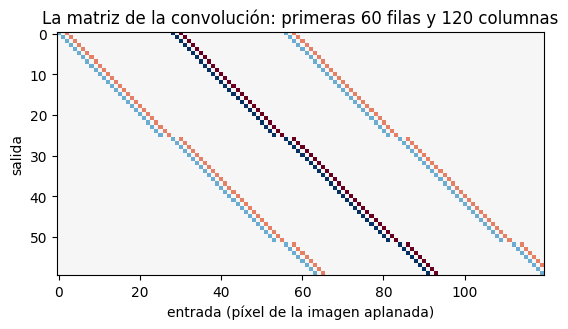

In [23]:
fig, eje = plt.subplots(figsize=(11, 3.4))
limite = matriz.abs().max().item()
eje.imshow(matriz[:60, :120], cmap="RdBu_r", vmin=-limite, vmax=limite, interpolation="nearest")
eje.set_xlabel("entrada (píxel de la imagen aplanada)")
eje.set_ylabel("salida")
eje.set_title("La matriz de la convolución: primeras 60 filas y 120 columnas")
plt.tight_layout()
plt.show()

Cada fila es la anterior corrida un lugar a la derecha, salvo cada 26 filas, cuando la ventana baja a la fila siguiente de la imagen y avanza tres lugares en vez de uno (de la columna 25 de una fila a la columna 0 de la siguiente, que en la imagen aplanada está 3 posiciones más allá). Cada fila tiene sus pesos en tres tramos separados por 28 columnas, porque las tres filas del filtro tocan tres filas de la imagen, y en la imagen aplanada una fila está 28 posiciones después de la anterior.

Goodfellow y otros llaman a estas dos ideas **interacciones ralas** y **parámetros compartidos**, y las ponen, junto con la equivariancia de la sección siguiente, como las tres ideas que motivan la convolución ([sección 9.2](https://www.deeplearningbook.org/contents/convnets.html)). El ahorro es enorme. Comparamos la primera capa de la sección 8 con una capa densa que entregue la misma cantidad de números:

In [24]:
entradas, salidas = 3 * 32 * 32, 32 * 32 * 32
convolucional = 32 * 3 * 3 * 3 + 32
densa = entradas * salidas + salidas
print(f"convolucional, 32 filtros de 3 × 3 × 3 : {miles(convolucional):>13s} parámetros")
print(f"densa de {miles(entradas)} a {miles(salidas)} valores   : {miles(densa):>13s} parámetros")
print(f"la densa tiene {densa / convolucional:,.0f} veces más".replace(",", "."))

convolucional, 32 filtros de 3 × 3 × 3 :           896 parámetros
densa de 3.072 a 32.768 valores   :   100.696.064 parámetros
la densa tiene 112.384 veces más


Más de cien millones de parámetros contra 896. Esa comparación mezcla los dos ahorros: las conexiones locales y los parámetros compartidos. CS231n mide solo el de compartir, con la primera capa de la red de Krizhevsky: con conexiones locales pero sin compartir, cada una de sus 290.400 neuronas tendría sus propios 364 parámetros, 105.705.600 en total; compartiendo un filtro por mapa, quedan 34.944.

Compartir parámetros es razonable porque, como dice CS231n, si detectar un borde horizontal sirve en un lugar de la imagen, debería servir también en otro. Los mismos apuntes advierten cuándo deja de serlo: en fotos de caras centradas, cabe esperar que en distintas zonas se aprendan rasgos distintos, propios de los ojos o del pelo. Goodfellow y otros ponen el mismo ejemplo ([sección 9.2](https://www.deeplearningbook.org/contents/convnets.html)): la parte de la red que procesa la parte de arriba de la cara tiene que buscar cejas, y la que procesa la de abajo, una barbilla.

## 11. Equivariancia a traslaciones

Compartir los pesos tiene una consecuencia. Goodfellow y otros la definen así ([sección 9.2](https://www.deeplearningbook.org/contents/convnets.html)): una función es **equivariante** a una transformación si transformar la entrada cambia la salida de la misma forma, $f(g(x)) = g(f(x))$. Para la convolución, $g$ es mover la imagen: si el objeto se mueve, su mapa se mueve lo mismo.

Lo comprobamos con la bota. Primero la ponemos en un lienzo negro más grande, para que al moverla no se salga nada del cuadro, y después la corremos 2 píxeles hacia abajo y 3 hacia la derecha:

In [25]:
def mover(imagen, abajo, derecha):
    """Corre la imagen rellenando con ceros lo que queda vacío."""
    alto, ancho = imagen.shape[-2:]
    return F.pad(imagen, (derecha, 0, abajo, 0))[..., :alto, :ancho]


lienzo = F.pad(bota, (4, 4, 4, 4)).view(1, 1, 36, 36)        # la bota con 4 píxeles negros por lado
filtro_v = filtros_borde[:1]                                  # el filtro de bordes verticales, [1, 1, 3, 3]

mover_y_convolucionar = F.conv2d(mover(lienzo, 2, 3), filtro_v)
convolucionar_y_mover = mover(F.conv2d(lienzo, filtro_v), 2, 3)
print("¿conv(mover(x)) = mover(conv(x))?", torch.allclose(mover_y_convolucionar, convolucionar_y_mover, atol=1e-6))

¿conv(mover(x)) = mover(conv(x))? True


Son idénticos: da lo mismo mover la imagen y después buscar bordes, que buscar bordes y después mover el mapa. Una capa densa no tiene esta propiedad. Con una capa densa al azar que entregue otra imagen del mismo tamaño:

In [26]:
torch.manual_seed(0)
densa = nn.Linear(36 * 36, 34 * 34)


def aplicar_densa(x):
    return densa(x.flatten(1)).view(1, 1, 34, 34)


with torch.no_grad():
    a = aplicar_densa(mover(lienzo, 2, 3))
    b = mover(aplicar_densa(lienzo), 2, 3)
print("¿densa(mover(x)) = mover(densa(x))?", torch.allclose(a, b, atol=1e-6))
print(f"diferencia relativa: {(a - b).norm() / b.norm():.2f}")

¿densa(mover(x)) = mover(densa(x))? False
diferencia relativa: 1.50


Con la capa densa, mover la entrada produce una salida que no tiene nada que ver con la anterior corrida. Por eso una red densa tiene que aprender cada trazo por separado en cada posición donde pueda aparecer, mientras que una convolución lo aprende una vez y lo reconoce en todas partes. Es lo que anticipaba `04-clasificacion-de-imagenes/02_experimentos_con_mnist` del módulo 2 al final de su sección 4: para la red densa, un dígito corrido unos píxeles es una imagen muy distinta (su ejercicio 6 lo mide con `torch.roll`).

La equivariancia está garantizada solo para traslaciones. Goodfellow y otros advierten que la convolución no es equivariante, en general, a otras transformaciones, como cambios de escala o rotaciones. Con una rotación de 90° y el filtro de bordes verticales:

In [27]:
girar_y_convolucionar = F.conv2d(torch.rot90(lienzo, 1, dims=(2, 3)), filtro_v)
convolucionar_y_girar = torch.rot90(F.conv2d(lienzo, filtro_v), 1, dims=(2, 3))
print("¿conv(girar(x)) = girar(conv(x))?", torch.allclose(girar_y_convolucionar, convolucionar_y_girar, atol=1e-6))

¿conv(girar(x)) = girar(conv(x))? False


Al girar la bota, sus bordes verticales pasan a ser horizontales, y el filtro de bordes verticales ya no los ve. La igualdad depende del filtro: uno que quede igual al girarlo 90°, como el que pide el ejercicio 6, sí la cumple. Pero los filtros que aprende una red no tienen por qué tener esa simetría, y en general no la tienen.

Equivariancia tampoco es lo mismo que **invariancia**: el mapa no queda igual, se mueve. Para que la respuesta final de la red dependa menos de la posición exacta hace falta otra pieza, el *pooling*, que viene en `01-arquitectura/01_la_arquitectura_de_una_cnn`. Esa invariancia es solo aproximada: tolera movimientos pequeños, no cualquiera.

## 12. La red aprende el filtro

En todo el notebook escribimos los filtros a mano. En una red convolucional nadie los escribe: son parámetros, y se ajustan por descenso de gradiente como los pesos de una capa densa. La idea central del video *CNNs – Part 1* del curso es justamente esa: la red aprende qué filtros le sirven.

Un experimento chico para verlo. Tomamos 100 imágenes de Fashion-MNIST, les aplicamos el filtro de Sobel de bordes verticales, y le pedimos a una capa `nn.Conv2d` con pesos al azar que reproduzca esos mapas. La pérdida es el error cuadrático medio entre su salida y los mapas de Sobel, y entrenamos con descenso de gradiente usando todas las imágenes en cada paso:

In [28]:
X = moda.data[:100].float().unsqueeze(1) / 255               # [100, 1, 28, 28]
Y = F.conv2d(X, sobel_vertical.view(1, 1, 3, 3))             # los mapas que queremos reproducir

torch.manual_seed(0)
aprendiz = nn.Conv2d(1, 1, kernel_size=3, bias=False)
optimizador = torch.optim.SGD(aprendiz.parameters(), lr=0.25)
print("filtro inicial:\n", aprendiz.weight.data.view(3, 3))

pasos_guardados = [0, 10, 100, 1000, 3000]
historia, instantaneas = [], {0: aprendiz.weight.data.view(3, 3).clone()}
for paso in range(1, 3001):
    perdida = F.mse_loss(aprendiz(X), Y)
    optimizador.zero_grad()
    perdida.backward()
    optimizador.step()
    error = (aprendiz.weight.data.view(3, 3) - sobel_vertical).abs().max().item()
    historia.append((perdida.item(), error))
    if paso in pasos_guardados:
        instantaneas[paso] = aprendiz.weight.data.view(3, 3).clone()

print("\nfiltro aprendido:\n", aprendiz.weight.data.view(3, 3))
print(f"\nerror máximo contra Sobel: {historia[-1][1]:.4f}")

filtro inicial:
 tensor([[-0.0025,  0.1788, -0.2743],
        [-0.2453, -0.1284,  0.0894],
        [-0.0066,  0.2643, -0.0296]])



filtro aprendido:
 tensor([[-1.0007e+00,  1.0095e-03,  9.9953e-01],
        [-1.9988e+00, -1.9166e-03,  2.0010e+00],
        [-1.0006e+00,  1.0919e-03,  9.9937e-01]])

error máximo contra Sobel: 0.0019


Partiendo de números al azar, la capa terminó con el filtro de Sobel: −1, −2, −1 a la izquierda, 0 al centro y 1, 2, 1 a la derecha, con un error de milésimas. Así se ve el camino:

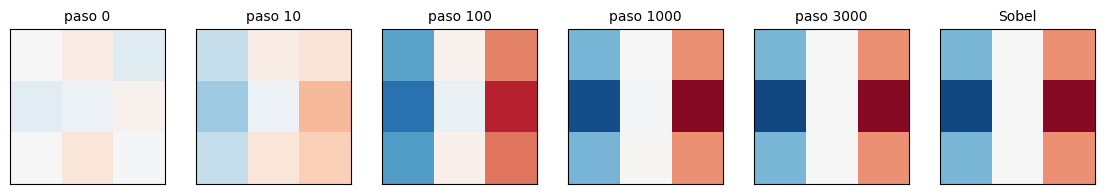

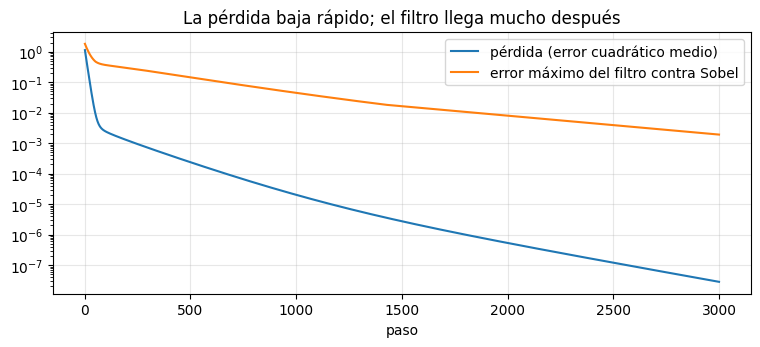

paso    1: pérdida 1.13e+00   error del filtro 1.8183
paso   10: pérdida 4.32e-01   error del filtro 1.2870
paso  100: pérdida 2.40e-03   error del filtro 0.3656
paso 1000: pérdida 2.02e-05   error del filtro 0.0448
paso 3000: pérdida 2.83e-08   error del filtro 0.0019


In [29]:
fig, ejes = plt.subplots(1, len(pasos_guardados) + 1, figsize=(14, 2.6))
for eje, paso in zip(ejes, pasos_guardados):
    eje.imshow(instantaneas[paso], cmap="RdBu_r", vmin=-2.2, vmax=2.2)
    eje.set_title(f"paso {paso}", fontsize=10)
ejes[-1].imshow(sobel_vertical, cmap="RdBu_r", vmin=-2.2, vmax=2.2)
ejes[-1].set_title("Sobel", fontsize=10)
for eje in ejes:
    eje.set_xticks([])
    eje.set_yticks([])
plt.show()

perdidas, errores = zip(*historia)
fig, eje = plt.subplots(figsize=(9, 3.4))
eje.semilogy(range(1, 3001), perdidas, label="pérdida (error cuadrático medio)")
eje.semilogy(range(1, 3001), errores, label="error máximo del filtro contra Sobel")
eje.set_xlabel("paso")
eje.legend()
eje.grid(alpha=0.3)
eje.set_title("La pérdida baja rápido; el filtro llega mucho después")
plt.show()

for paso in [1, 10, 100, 1000, 3000]:
    print(f"paso {paso:4d}: pérdida {historia[paso - 1][0]:.2e}   error del filtro {historia[paso - 1][1]:.4f}")

Hay algo raro en la segunda figura. En 100 pasos la pérdida bajó de 1.13 a 0.0024, unas 470 veces, pero el filtro todavía tiene errores de más de un tercio; los últimos decimales toman miles de pasos. ¿Por qué el modelo reproduce casi perfecto los mapas con un filtro que todavía está bastante mal?

La respuesta está en la geometría de la pérdida, que vimos en `03-optimalidad/01_optimalidad` del módulo 1 (sección 7). Cada valor de la salida es el producto de los 9 píxeles de una ventana por los 9 pesos, así que la pérdida es una función **cuadrática** de los pesos, con hessiano $\frac{2}{M} P^\top P$, donde $P$ tiene una fila por ventana. `F.unfold` arma esa matriz de ventanas:

In [30]:
P = F.unfold(X, kernel_size=3).transpose(1, 2).reshape(-1, 9)     # una fila por ventana de 3 × 3
hessiano = 2 / len(P) * P.T @ P
autovalores, autovectores = torch.linalg.eigh(hessiano)

print("ventanas:", miles(len(P)))
print("autovalores:", [round(v, 4) for v in autovalores.tolist()])
print(f"número de condición: {autovalores[-1] / autovalores[0]:.0f}")
print(f"tasa usada 0.25 contra 2 / λ_max = {2 / autovalores[-1]:.3f}")

ventanas: 67.600
autovalores: [0.0057, 0.011, 0.0126, 0.0246, 0.0351, 0.0622, 0.1047, 0.2089, 3.7113]
número de condición: 649
tasa usada 0.25 contra 2 / λ_max = 0.539


El número de condición es de unos 650: un valle muy angosto. La tasa de 0.25 está cerca de $1/\lambda_\text{max} \approx 0.27$ y por debajo del límite $2/\lambda_\text{max}$, así que el descenso no diverge, y la dirección más curva se resuelve en pocos pasos. Pero en la más plana el error se multiplica en cada paso por $1 - 0.25\,\lambda_\text{min} \approx 0.9986$: hacen falta cientos de pasos para reducirlo apenas a la mitad.

¿Qué direcciones son esas? Cada autovector es un filtro de 3 × 3:

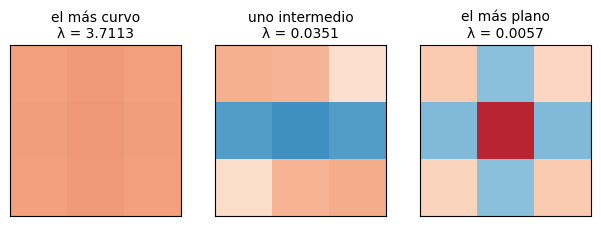

autovector más curvo:
 tensor([[0.3300, 0.3400, 0.3300],
        [0.3300, 0.3500, 0.3400],
        [0.3300, 0.3400, 0.3300]])


In [31]:
fig, ejes = plt.subplots(1, 3, figsize=(7.5, 2.6))
for eje, indice, nombre in zip(ejes, [8, 4, 0], ["el más curvo", "uno intermedio", "el más plano"]):
    vector = autovectores[:, indice].view(3, 3)
    vector = vector * vector.sum().sign() if vector.sum().abs() > 1e-3 else vector
    eje.imshow(vector, cmap="RdBu_r", vmin=-0.8, vmax=0.8)
    eje.set_title(f"{nombre}\nλ = {autovalores[indice]:.4f}", fontsize=10)
    eje.set_xticks([])
    eje.set_yticks([])
plt.show()
print("autovector más curvo:\n", autovectores[:, 8].view(3, 3).abs().round(decimals=2))

- La dirección **más curva** es casi un promedio parejo de los 9 píxeles. En una foto los píxeles vecinos se parecen, así que lo que más pesa en cada ventana es su brillo medio. Cualquier error del filtro en esa dirección cambia mucho la salida, y el descenso lo corrige en seguida.
- La dirección **más plana** es un patrón que alterna signos de un píxel al siguiente, un tablero de ajedrez. En imágenes reales casi no hay cambios tan bruscos entre píxeles vecinos, así que un error del filtro en esa dirección casi no se nota en la salida. Por eso la pérdida queda bajísima con el filtro todavía mal, y el gradiente casi no empuja a corregirlo.

Como el problema es lineal, también se puede resolver de un golpe con mínimos cuadrados, las ecuaciones normales de `03-optimalidad/01_optimalidad` (sección 6):

In [32]:
exacto = torch.linalg.lstsq(P, Y.reshape(-1, 1)).solution.view(3, 3)
print(exacto)
print(f"error máximo contra Sobel: {(exacto - sobel_vertical).abs().max():.1e}")

tensor([[-1.0000e+00,  1.9195e-06,  1.0000e+00],
        [-2.0000e+00, -2.7747e-06,  2.0000e+00],
        [-1.0000e+00,  1.1076e-06,  1.0000e+00]])
error máximo contra Sobel: 2.8e-06


Da el filtro de Sobel hasta el error de redondeo. En una red de verdad no hay mapas objetivo que copiar: los filtros se ajustan para bajar la pérdida de clasificación, y nadie le dice a la red qué rasgo buscar. Lo veremos en `02-entrenamiento/01_una_cnn_para_la_naturaleza`. Pero el mecanismo es el mismo: los filtros son pesos, y el descenso de gradiente los mueve hacia lo que sirve.

## 13. Resumen

- Una capa densa no escala a fotos: una sola neurona sobre una imagen de 224 × 224 × 3 tiene 150.528 pesos, y no sabe qué píxeles son vecinos.
- Una **convolución** desliza un filtro chico sobre la imagen; en cada posición multiplica y suma. El resultado es un **mapa de características**: dónde aparece el rasgo que busca el filtro.
- PyTorch calcula la **correlación cruzada** (sin voltear el filtro) y la llama convolución. Como los filtros se aprenden, da igual.
- Un filtro de bordes verticales es una derivada horizontal suavizada: positivo donde la imagen se aclara hacia la derecha, negativo donde se oscurece, cero en regiones parejas.
- Con varios canales, cada filtro tiene un juego de pesos por canal y **suma** los resultados: produce un solo mapa. Un filtro de 1 × 1 combina canales sin mirar vecinos.
- `nn.Conv2d(entrada, salida, k)` tiene pesos `[salida, entrada, k, k]` y un sesgo por filtro, inicializados con $\mathcal{U}(-\sqrt{k'}, \sqrt{k'})$, $k' = 1/(\text{entrada} \cdot k^2)$. La cantidad de parámetros no depende del tamaño de la imagen.
- Tamaño de la salida: $\lfloor (W + 2P - F) / S \rfloor + 1$. Relleno $(F - 1)/2$ conserva el tamaño con paso 1; paso 2 lo reduce a la mitad. Si la división no es exacta, PyTorch ignora en silencio las últimas filas y columnas.
- Una convolución es una capa densa con **conexiones locales** y **parámetros compartidos**: 896 parámetros en lugar de más de cien millones.
- La convolución es **equivariante a traslaciones** (mover la entrada mueve el mapa), pero en general no a rotaciones ni a cambios de escala: depende del filtro.
- Los filtros se aprenden por descenso de gradiente. Las direcciones que casi no aparecen en las imágenes naturales, como los patrones de tablero, se aprenden mucho más lento.

## Ejercicios

1. Antes de ejecutar nada: una entrada de 1 × 28 × 28 pasa por `nn.Conv2d(1, 8, 5)` y después por `nn.Conv2d(8, 16, 3, stride=2, padding=1)`. ¿Qué forma tiene la salida y cuántos parámetros tiene cada capa? Compruébalo.
2. Aplica a la bota el filtro de la sección 3, con unos a la izquierda y menos unos a la derecha. ¿Por qué su mapa tiene el signo contrario al de Sobel? ¿Qué cambia por no tener el 2 en la fila central?
3. Diseña un filtro de 3 × 3 que detecte bordes diagonales y aplícalo al girasol con `nn.Conv2d(1, 1, 3, padding=1, padding_mode="replicate")`, que rellena copiando el píxel de la orilla en vez de poner ceros. ¿Qué pasa con los bordes falsos del marco?
4. Escribe una convolución de 1 × 1 con 3 canales de entrada que dé valores altos en lo amarillo y bajos en lo verde. Aplícala al girasol. (Pista: el amarillo tiene rojo y verde altos y azul bajo.)
5. En la sección 12, normaliza las 100 imágenes (resta su media y divide por su desviación) antes de calcular los mapas objetivo. Predice qué pasa con el autovalor más grande y con el número de condición, y comprueba cuántos pasos hacen falta ahora para llegar a un error de 0.01.
6. Repite la comprobación de la rotación de la sección 11 con el filtro laplaciano `[[0, 1, 0], [1, -4, 1], [0, 1, 0]]`. ¿Se cumple ahora `conv(girar(x)) = girar(conv(x))`? ¿Qué propiedad del filtro lo explica? ¿Pasa lo mismo con un giro de 45°?
7. Cuenta los parámetros de `nn.Conv2d(64, 128, 3, padding=1)` y los de una capa densa que lleve un volumen de 64 × 16 × 16 a uno de 128 × 16 × 16. ¿Cuántas veces más grande es la densa?

## Fuentes

Las citas textuales que respaldan cada afirmación, con el lugar exacto donde están. Las páginas se revisaron el 22 de octubre de 2026.

**Del material del curso**

- **CS231n**, [*Convolutional Neural Networks (CNNs / ConvNets)*](https://cs231n.github.io/convolutional-networks/), apuntes del curso de Stanford (lecturas del módulo 4):
  - *Architecture Overview*: "Regular Neural Nets don’t scale well to full images", "an image of more respectable size, e.g. 200x200x3, would lead to neurons that have 200*200*3 = 120,000 weights" y "the huge number of parameters would quickly lead to overfitting" (sección 2).
  - *Convolutional Layer*, *Local Connectivity*: "The connections are local in 2D space (along width and height), but always full along the entire depth of the input volume" (sección 7).
  - *Spatial arrangement*: "the correct formula for calculating how many neurons “fit” is given by \((W - F + 2P)/S + 1\)", "For example for a 7x7 input and a 3x3 filter with stride 1 and pad 0 we would get a 5x5 output. With stride 2 we would get a 3x3 output" (sección 9).
  - *Use of zero-padding*: "setting zero padding to be \(P = (F - 1)/2\) when the stride is \(S = 1\) ensures that the input volume and output volume will have the same size spatially"; y *Summary*: "A common setting of the hyperparameters is \(F = 3, S = 1, P = 1\)" (sección 9).
  - *Constraints on strides*: "\((W - F + 2P)/S + 1 = (10 - 3 + 0) / 2 + 1 = 4.5\)" y "a ConvNet library could throw an exception or zero pad the rest to make it fit, or crop the input to make it fit" (sección 9).
  - *Real-world example*: "accepted images of size [227x227x3]. On the first Convolutional Layer, it used neurons with receptive field size \(F = 11\), stride \(S = 4\) and no zero padding \(P = 0\). Since (227 - 11)/4 + 1 = 55" (sección 9).
  - *Parameter Sharing*: "this adds up to 290400 * 364 = 105,705,600 parameters on the first layer of the ConvNet alone", "for a total of 96*11*11*3 = 34,848 unique weights, or 34,944 parameters (+96 biases)", "If detecting a horizontal edge is important at some location in the image, it should intuitively be useful at some other location as well", "One practical example is when the input are faces that have been centered in the image" y "You might expect that different eye-specific or hair-specific features could (and should) be learned in different spatial locations" (sección 10).
- **Goodfellow, Bengio y Courville**, [*Deep Learning*, capítulo 9: *Convolutional Networks*](https://www.deeplearningbook.org/contents/convnets.html) (2016; está en las lecturas del módulo 1):
  - Sección 9.1: la convolución "$S(i, j) = (K * I)(i, j) = \sum_m \sum_n I(i - m, j - n) K(m, n)$" (ecuación 9.5), la correlación cruzada "which is the same as convolution but without flipping the kernel" (ecuación 9.6), "Many machine learning libraries implement cross-correlation but call it convolution" y "an algorithm based on convolution with kernel flipping will learn a kernel that is flipped relative to the kernel learned by an algorithm without the flipping" (sección 5).
  - Sección 9.2: "Convolution leverages three important ideas that can help improve a machine learning system: sparse interactions, parameter sharing and equivariant representations", "To say a function is equivariant means that if the input changes, the output changes in the same way", "a function f(x) is equivariant to a function g if f(g(x)) = g(f(x))", "the part of the network processing the top of the face needs to look for eyebrows, while the part of the network processing the bottom of the face needs to look for a chin" y "Convolution is not naturally equivariant to some other transformations, such as changes in the scale or rotation of an image" (secciones 10 y 11).
  - Sección 9.10: "Their great discovery was that neurons in the early visual system responded most strongly to very specific patterns of light, such as precisely oriented bars, but responded hardly at all to other patterns", "A simple cell’s activity can to some extent be characterized by a linear function of the image in a small, spatially localized receptive field" y "The detector units of a convolutional network are designed to emulate these properties of simple cells" (sección 2).

**Documentación**

- [`torch.nn.Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html): "where ⋆ is the valid 2D cross-correlation operator"; la salida es "bias(C_out_j) + Σ_k weight(C_out_j, k) ⋆ input(N_i, k)", con la suma sobre los canales de entrada; "padding='same' pads the input so the output has the shape as the input. However, this mode doesn’t support any stride values other than 1"; la fórmula de $H_\text{out}$ en *Shape*; y en *Variables*, los pesos tienen forma "(out_channels, in_channels/groups, kernel_size[0], kernel_size[1])" y "are sampled from $\mathcal{U}(-\sqrt{k}, \sqrt{k})$ where $k = \frac{groups}{C_\text{in} * \prod_{i=0}^{1}\text{kernel\_size}[i]}$" (secciones 5, 7, 8 y 9).
- [`torch.nn.functional.conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.conv2d.html): "input – input tensor of shape (minibatch, in_channels, iH, iW)" y "weight – filters of shape (out_channels, in_channels/groups, kH, kW)" (sección 4).
- Pillow, [`Image.convert`](https://pillow.readthedocs.io/en/stable/reference/Image.html#PIL.Image.Image.convert): "When translating a color image to grayscale (mode “L”), the library uses the ITU-R 601-2 luma transform: L = R * 299/1000 + G * 587/1000 + B * 114/1000" (secciones 6 y 7).

**Lo que no viene de una fuente** son los números de este notebook (las cuentas de parámetros, las comprobaciones, los mapas, la matriz de la convolución y el experimento de aprender el filtro): todos salen de las celdas de código. También son nuestros el análisis del hessiano de la sección 12 y la interpretación de sus autovectores, la comprobación con autograd de la columna que nunca se mira y la descomposición del filtro de Sobel como producto de dos vectores. Que la red aprende sus propios filtros es la idea del video *CNNs – Part 1* del curso.